In [5]:
import torch
import torch.nn as nn
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.__version__)
print(device)

2.13.0+cu126
cuda


In [ ]:
#3-1
torch.manual_seed(0)
layer = nn.Linear(784, 100)
print(layer.weight.shape)
print(layer.bias.shape)
n = sum(p.numel() for p in layer.parameters())
print(n)
x = torch.randn(64, 784)
print(layer(x).shape)

torch.Size([100, 784])
torch.Size([100])
78500
torch.Size([64, 100])


In [7]:
print(layer.weight[0, :5])

print(layer.bias[0])

print(layer.weight.requires_grad)

tensor([-0.0003,  0.0192, -0.0294, -0.0263, -0.0138], grad_fn=<SliceBackward0>)
tensor(-0.0354, grad_fn=<SelectBackward0>)
True


In [9]:
layer = nn.Linear(20, 30)
print(sum(p.numel() for p in layer.parameters()))

print(layer.weight.shape)

print(layer(torch.randn(64, 20)).shape)

630
torch.Size([30, 20])
torch.Size([64, 30])


In [ ]:
#3-2
z = torch.tensor([-2., -1., 0., 1., 2.])
print(torch.relu(z))

print(torch.sigmoid(z))

tensor([0., 0., 0., 1., 2.])
tensor([0.1192, 0.2689, 0.5000, 0.7311, 0.8808])


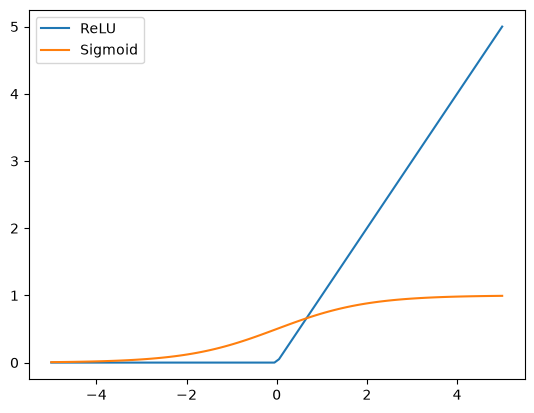

0.0
1.0


In [13]:
import matplotlib.pyplot as plt

z = torch.linspace(-5, 5, 100)
plt.plot(z, torch.relu(z), label = "ReLU")
plt.plot(z, torch.sigmoid(z), label = "Sigmoid")
plt.legend()
plt.show()

print(torch.relu(torch.tensor(-3.7)).item())
print(torch.sigmoid(torch.tensor(100.)).item())

In [ ]:
#3-3
import torch
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 100)
        self.act = nn.ReLU()
        self.fc2 = nn.Linear(100, 10)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

torch.manual_seed(0)
model = MLP()
print(sum(p.numel() for p in model.parameters()))
print(model(torch.randn(64, 784)).shape)

79510
torch.Size([64, 10])


In [18]:
import torch
import torch.nn as nn

class MLP2(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.act = nn.ReLU()
        self.fc2 = nn.Linear(256, 10)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

torch.manual_seed(0)
model = MLP2()
print(sum(p.numel() for p in model.parameters()))
print(model(torch.randn(8, 784)).shape)

203530
torch.Size([8, 10])


In [20]:
#3-4
import torch
import torch.nn as nn

torch.manual_seed(0)
fc1, act, fc2 = nn.Linear(784, 100), nn.ReLU(), nn.Linear(100, 10)
x = torch.randn(64, 784)
h = fc1(x); print(h.shape)
h = act(h); print(h.shape)
out = fc2(h); print(out.shape)
print(out[0].argmax().item())

torch.Size([64, 100])
torch.Size([64, 100])
torch.Size([64, 10])
3


In [21]:
import torch
import torch.nn as nn

layer = nn.Linear(784, 100)
print(layer(torch.randn(32, 784)).shape)

print(3 * 32 * 32)

torch.Size([32, 100])
3072


In [25]:
#3-5
import torch
from torchvision import datasets, transforms

train_all = datasets.MNIST(root = 'data', train = True, download = True, transform = transforms.ToTensor())

from torch.utils.data import DataLoader, random_split

g = torch.Generator().manual_seed(0)
train_set, val_set = random_split(train_all, [50000, 10000], generator = g)

train_loader = DataLoader(train_set, batch_size = 64, shuffle = True)
val_loader = DataLoader(val_set, batch_size = 256, shuffle = False)

torch.manual_seed(0)
model = MLP().to(device)
opt = torch.optim.SGD(model.parameters(), lr = 0.1)
loss_fn = nn.CrossEntropyLoss()
for epoch in range(3):
    for x, y in train_loader:
        x, y = x.view(-1, 784).to(device), y.to(device)
        loss = loss_fn(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    correct = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.view(-1, 784).to(device), y.to(device)
            correct += (model(x).argmax(dim = 1) == y).sum().item()
    print(epoch + 1, round(correct / 10000 * 100, 1))

1 91.0
2 93.9
3 93.0
